RESUMO DA BIBLIOTECA PANDAS

In [1]:
import pandas as pd

# CRIANDO DATAFRAMES
# Criando um DataFrame por didionario
# pode ser passado como parâmentro um json lido pela biblioteca requests
# dados_dicionario = [
#     {
#         'nome': None,
#         'idade': None,
#         'salario': '',
#     },
#         {
#         'nome': '',
#         'idade': '',
#         'salario': '',
#     }
# ]
# df_dados = pd.DataFrame(dados_dicionario)

df_pratica = pd.read_csv('dados_pratica.csv') # DataFrame
# print(df_pratica)

# TRATANDO DADOS DF
df_apagando_linhas = df_pratica.dropna()

df_preenchendo_por_media = df_pratica["salario"].fillna(
    df_pratica["salario"].mean()
)

df_dados_limpos = df_pratica.fillna(
    {
        'salario': df_pratica["salario"].mean().round(2),
        'idade': 30
    }
)

print("DF DADOS LIMPOS")
print(df_dados_limpos.info()) # informa nossas colunas, tipos de dados e quantidade de null/NA


DF DADOS LIMPOS
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id_funcionario  50 non-null     int64  
 1   idade           50 non-null     float64
 2   departamento    50 non-null     str    
 3   salario         50 non-null     float64
 4   cidade          50 non-null     str    
 5   vendas_mensais  50 non-null     int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 2.5 KB
None


In [2]:
# FILTRAGEM DE DADOS

salario_entre_mil_e_tres_mil = df_pratica[
    (df_pratica["salario"] > 1000) &
    (df_pratica["salario"] < 3000)
]
# valor > valor = True

print(salario_entre_mil_e_tres_mil)

    id_funcionario  idade departamento  salario          cidade  \
5                6   56.0       Vendas  2656.32    Porto Alegre   
17              18   41.0    Marketing  2922.62  Belo Horizonte   
27              28   59.0           RH  2700.86        Curitiba   
42              43   43.0    Marketing  2927.83  Belo Horizonte   
45              46   45.0       Vendas  2595.66    Porto Alegre   

    vendas_mensais  
5               36  
17              17  
27               7  
42               5  
45              43  


In [3]:
tabela_dinamica = pd.pivot_table( # funciona como um groupby mais versátil
    df_pratica,
    index="cidade",
    values="vendas_mensais",
    columns="departamento",
    aggfunc="sum"
)
tabela_vendas_departamente = df_pratica.groupby(
    ["cidade", "departamento"]
)["vendas_mensais"].sum()

print(tabela_dinamica)
print(tabela_vendas_departamente)

departamento    Diretoria  Financeiro  Marketing    RH   TI  Vendas
cidade                                                             
Belo Horizonte        NaN        13.0       22.0  12.0  3.0    67.0
Curitiba              NaN        20.0       24.0  20.0  5.0    98.0
Porto Alegre          9.0         NaN        5.0  43.0  0.0   114.0
Rio de Janeiro        7.0         8.0       23.0   NaN  NaN    65.0
São Paulo             2.0        19.0       15.0  19.0  0.0    50.0
cidade          departamento
Belo Horizonte  Financeiro       13
                Marketing        22
                RH               12
                TI                3
                Vendas           67
Curitiba        Financeiro       20
                Marketing        24
                RH               20
                TI                5
                Vendas           98
Porto Alegre    Diretoria         9
                Marketing         5
                RH               43
                TI         

In [4]:
import numpy as np

lista_pythton = [1, 2, 3, 4, 5, 6]
print(f"lista do pyhton {lista_pythton}")

array1 = np.array([10, 20, 30, 40, 50])
array2 = np.array([20, 40, 60, 80, 100])

print(array1 + array2)

lista do pyhton [1, 2, 3, 4, 5, 6]
[ 30  60  90 120 150]


In [5]:
vendas = df_pratica["vendas_mensais"].values
print(f'Médias por Numpy {np.mean(vendas)}')
print(f"Apenas vendas acima de 10 Numpy {np.mean(vendas > 10)}")
print(f"Apenas vendas acima de 10 pelo python {(vendas.mean() > 10)}")
# print(f"Apenas vendas acima de 10 {
#     np.where(vendas > 10, True, False)
# }")
df_pratica["meta"] = np.where(vendas, "Atingiu meta", "Falhou na meta")
print(df_pratica.to_string())

Médias por Numpy 13.26
Apenas vendas acima de 10 Numpy 0.46
Apenas vendas acima de 10 pelo python True
    id_funcionario  idade departamento   salario          cidade  vendas_mensais            meta
0                1   56.0           RH   3400.55  Belo Horizonte              12    Atingiu meta
1                2   46.0           TI   4486.21       São Paulo               0  Falhou na meta
2                3   32.0    Marketing       NaN  Rio de Janeiro              14    Atingiu meta
3                4   25.0       Vendas   3382.82  Rio de Janeiro              39    Atingiu meta
4                5   38.0           TI   5817.87        Curitiba               2    Atingiu meta
5                6   56.0       Vendas   2656.32    Porto Alegre              36    Atingiu meta
6                7   36.0           TI   4558.23  Belo Horizonte               0  Falhou na meta
7                8   40.0    Diretoria  14831.67       São Paulo               2    Atingiu meta
8                9   28.

In [6]:
calculo_percentual = np.percentile(vendas, 12)
print(f"12% das vendas foram até {calculo_percentual} de unidades")

12% das vendas foram até 2.0 de unidades


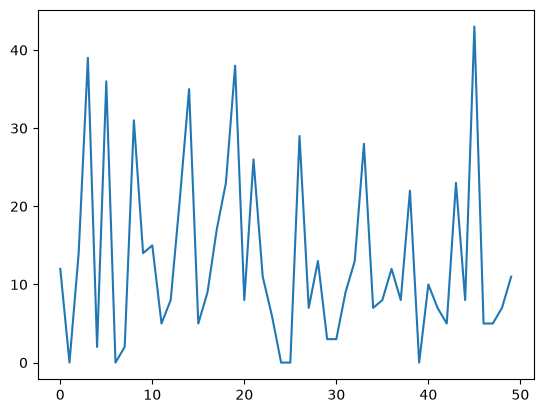

In [9]:
import matplotlib.pyplot as plt

plt.plot(vendas)
plt.show()

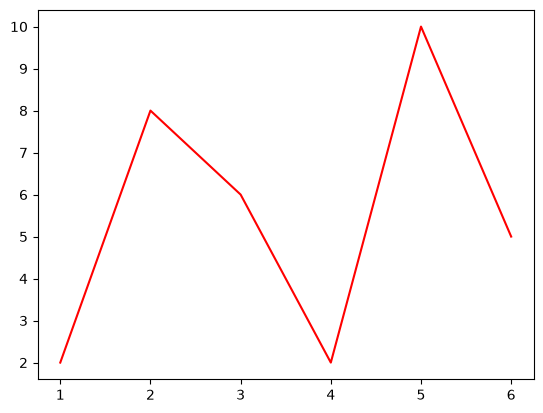

In [13]:
import matplotlib.pyplot as plt

linhax = [1,2,3,4,5,6]
linhay = [2,8,6,2,10,5]

plt.plot(
    linhax,
    linhay,
    color='red',
)

plt.show()